# 03 · Gustos: recomendador y familias de juegos
**Responsable:** Fabiola

**Entrada:** `juegos.parquet`

**Salida:** `src/recomendador.py` con `recomendar(favoritos, k)` y `similitud(favoritos)`; `outputs/clusters.csv` (appid, cluster, familia)

**Pasos:**
1. Matriz de etiquetas + géneros: cada juego es una fila de 0 y 1.
2. Similitud coseno contra el perfil promedio de los favoritos; ejemplo "si te gustó DOOM".
3. k-Means para varios k, elegir con silhouette (en una muestra, porque tarda).
4. PCA 2D coloreado por cluster; nombrar cada familia por sus etiquetas dominantes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # para poder importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.datos import cargar_juegos

df = cargar_juegos()
df.shape

(44568, 37)

## 1. Cada juego como un vector de etiquetas
Igual que las palabras de la clase 21 (es_animal, tamano, tiene_motor), cada juego se describe con números: una columna por género o etiqueta, con 1 si el juego la tiene. Se ignoran las etiquetas que aparecen en menos de `C.MIN_JUEGOS_ETIQUETA` juegos, porque son ruido. La matriz se arma en `src/recomendador.py` para que el notebook 05 use exactamente la misma.

In [2]:
from src.recomendador import matriz_gustos, recomendar, similitud

juegos, M = matriz_gustos()
print("juegos:", M.shape[0], "| columnas (géneros + etiquetas):", M.shape[1])
print("etiquetas por juego, promedio:", M.sum(axis=1).mean().round(1))
M.mean().sort_values(ascending=False).head(10).round(2)

juegos: 44568 | columnas (géneros + etiquetas): 429
etiquetas por juego, promedio: 17.6


gen_Indie           0.71
tag_Singleplayer    0.59
tag_Indie           0.59
tag_Adventure       0.45
tag_Action          0.44
gen_Adventure       0.43
gen_Action          0.42
tag_Casual          0.40
gen_Casual          0.36
tag_2D              0.30
dtype: float64

## 2. Recomendador: "si te gustó DOOM..."
El perfil del usuario es el promedio de los vectores de sus favoritos. Después se mide el parecido de cada juego con ese perfil usando similitud coseno: 1 = apuntan igual, 0 = nada que ver. Es el mismo `mas_parecidos` de la clase 21, pero con juegos.

In [3]:
recomendar(["DOOM"], k=10)

,appid,nombre,similitud
0,1098293,DOOM Eternal: The Ancient Gods - Part Two,0.816
1,782330,DOOM Eternal,0.810
2,214870,Painkiller Hell & Damnation,0.810
3,360,Half-Life Deathmatch: Source,0.781
4,9050,DOOM 3,0.762
5,39530,Painkiller: Black Edition,0.762
6,3270,Painkiller Overdose,0.758
7,1098292,DOOM Eternal: The Ancient Gods - Part One,0.726
8,2310,Quake,0.714
9,208200,DOOM 3,0.714


In [4]:
# Con dos favoritos muy distintos, el perfil promedio queda a medio camino
recomendar(["Stardew Valley", "Hollow Knight"], k=8)

,appid,nombre,similitud
0,790360,WarriOrb,0.764
1,814680,Unbound: Worlds Apart,0.743
2,1193760,WarriOrb: Prologue,0.723
3,1098080,3000th Duel,0.716
4,1891740,Lost Wish: In the desperate world,0.700
5,668550,8Doors: Arum's Afterlife Adventure,0.688
6,356650,Death's Gambit: Afterlife,0.685
7,727510,Void Memory,0.676


In [5]:
# Para el notebook 05: el parecido de TODOS los juegos (índice = appid)
s = similitud(["DOOM"])
print("juegos con similitud:", len(s))
s.describe().round(3)

juegos con similitud: 44567


count    44567.000
mean         0.150
std          0.115
min          0.000
25%          0.056
50%          0.137
75%          0.218
max          0.816
Name: similitud, dtype: float64

## 3. Familias de juegos con k-Means
Primero se probó k-Means directo sobre las columnas de 0 y 1: el silhouette quedó en 0.04 o menos, casi como puntos al azar (clase 20). Con tantas columnas de 0 y 1, todas las distancias se parecen.

Por eso se hace como en la clase 21: cada fila se lleva a largo 1 (así la distancia se comporta como la similitud coseno) y se resume con PCA en `C.N_COMPONENTES_PCA` ejes. k-Means se corre sobre esos ejes.

In [6]:
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = normalize(M.to_numpy().astype(float))
pca = PCA(n_components=C.N_COMPONENTES_PCA, random_state=C.SEMILLA).fit(X)
Z = pca.transform(X)
print(f"información que conservan {C.N_COMPONENTES_PCA} ejes: {pca.explained_variance_ratio_.sum():.0%}")

rng = np.random.default_rng(C.SEMILLA)
muestra = rng.choice(len(Z), C.MUESTRA_SILHOUETTE, replace=False)
sil = {}
for k in C.K_CLUSTERS:
    etiquetas_k = KMeans(n_clusters=k, n_init=5, random_state=C.SEMILLA).fit_predict(Z)
    sil[k] = silhouette_score(Z[muestra], etiquetas_k[muestra])
sil = pd.Series(sil, name="silhouette").round(3)
print(sil.to_string())

información que conservan 10 ejes: 35%


3     0.142
4     0.140
5     0.145
6     0.134
7     0.133
8     0.140
9     0.144
10    0.143
11    0.147
12    0.144


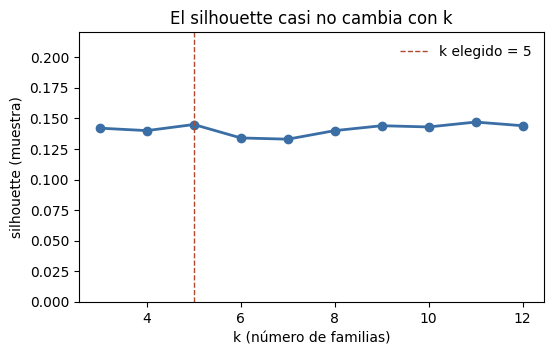

In [7]:
AZUL, ROJO, GRIS, VERDE = "#3A6EA5", "#B04A2E", "#75808E", "#2F6B4E"
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sil.index, sil.values, marker="o", color=AZUL, lw=2)
ax.axvline(C.K_FAMILIAS, color=ROJO, ls="--", lw=1, label=f"k elegido = {C.K_FAMILIAS}")
ax.set_ylim(0, sil.max() * 1.5)
ax.set_xlabel("k (número de familias)")
ax.set_ylabel("silhouette (muestra)")
ax.set_title("El silhouette casi no cambia con k")
ax.legend(frameon=False)
fig.savefig(C.FIGURAS / "03_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

El silhouette queda casi plano: ningún k separa mucho mejor que otro. Se elige `C.K_FAMILIAS` porque empata con el mejor valor y sus familias se pueden nombrar. Un silhouette tan bajo dice que los juegos no forman grupos muy separados: son un continuo, y un juego puede quedar entre dos familias.

In [8]:
km = KMeans(n_clusters=C.K_FAMILIAS, n_init=10, random_state=C.SEMILLA).fit(Z)
cluster = km.labels_

# El nombre sale de la tabla (clase 20): las etiquetas que más sobresalen en cada familia
def limpiar(c):
    return c.replace("gen_", "").replace("tag_", "")

perfil = []
for g in range(C.K_FAMILIAS):
    m = cluster == g
    sobresale = (M[m].mean() - M.mean()).nlargest(8)
    unicas = list(dict.fromkeys(limpiar(c) for c in sobresale.index))[:4]
    conocidos = juegos[m].sort_values("total_resenas", ascending=False)["nombre"].head(3).tolist()
    perfil.append({"cluster": g, "juegos": int(m.sum()), "familia": " / ".join(unicas[:2]),
                   "etiquetas que sobresalen": ", ".join(unicas), "ejemplos": ", ".join(conocidos)})
perfil = pd.DataFrame(perfil).set_index("cluster")
perfil

,juegos,familia,etiquetas que sobresalen,ejemplos
cluster,,,,
0,12336,Action / Shooter,"Action, Shooter, Arcade, Platformer","Counter-Strike 2, PUBG: BATTLEGROUNDS, Grand T..."
1,8123,Adventure / Atmospheric,"Adventure, Atmospheric, Horror, Story Rich","Red Dead Redemption 2, The Forest, Lethal Company"
2,8794,Casual / Puzzle,"Casual, Puzzle, Relaxing, Cute","Human Fall Flat, The Sims™ 4, Balatro"
3,7480,RPG / Fantasy,"RPG, Fantasy, Adventure, Action RPG","Terraria, Black Myth: Wukong, ELDEN RING"
4,7835,Simulation / Strategy,"Simulation, Strategy, Management, Building","Dota 2, Garry's Mod, Stardew Valley"


## 4. Mapa PCA en 2D
Para dibujar se usan los dos primeros ejes de PCA, sobre una muestra para que el dibujo no quede saturado.

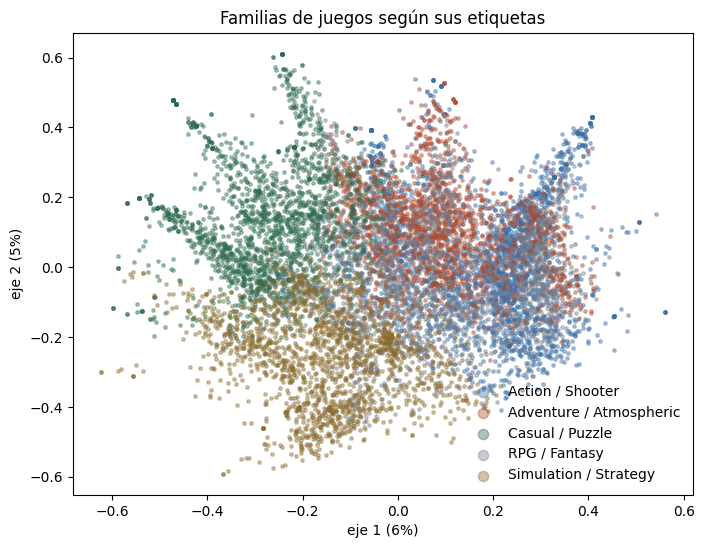

eje 1 | negativo: ['Casual', 'Casual', 'Simulation'] | positivo: ['Adventure', 'Action', 'Action']
eje 2 | negativo: ['Strategy', 'Strategy', 'Simulation'] | positivo: ['Adventure', 'Indie', 'Indie']


In [9]:
mapa = PCA(n_components=2, random_state=C.SEMILLA).fit(X)
xy = mapa.transform(X)
colores = [AZUL, ROJO, VERDE, GRIS, "#8C6D31", "#5B3F8C", "#2A7F8F"]

fig, ax = plt.subplots(figsize=(8, 6))
for g in range(C.K_FAMILIAS):
    m = np.where(cluster == g)[0]
    m = m[np.isin(m, muestra)]
    ax.scatter(xy[m, 0], xy[m, 1], s=6, alpha=0.4, color=colores[g % len(colores)],
               label=perfil.loc[g, "familia"])
ax.set_xlabel(f"eje 1 ({mapa.explained_variance_ratio_[0]:.0%})")
ax.set_ylabel(f"eje 2 ({mapa.explained_variance_ratio_[1]:.0%})")
ax.set_title("Familias de juegos según sus etiquetas")
ax.legend(frameon=False, markerscale=3)
fig.savefig(C.FIGURAS / "03_mapa_pca.png", dpi=150, bbox_inches="tight")
plt.show()

# ¿Qué mezcla cada eje? (clase 21: el nombre del eje sale de las columnas que más pesan)
pesos = pd.DataFrame(mapa.components_.T, index=[limpiar(c) for c in M.columns], columns=["eje 1", "eje 2"])
for eje in pesos:
    orden = pesos[eje].sort_values()
    print(eje, "| negativo:", list(orden.index[:3]), "| positivo:", list(orden.index[-3:]))

In [10]:
salida = pd.DataFrame({"appid": M.index, "cluster": cluster})
salida["familia"] = salida["cluster"].map(perfil["familia"])
salida.to_csv(C.OUTPUTS / "clusters.csv", index=False)
print("guardado:", C.OUTPUTS / "clusters.csv", "|", len(salida), "juegos")
salida["familia"].value_counts()

guardado:

 C:\Users\rodri\UFM\6toSemestre\DataScience\Data_science_final\outputs\clusters.csv | 44568 juegos


familia
Action / Shooter           12336
Casual / Puzzle             8794
Adventure / Atmospheric     8123
Simulation / Strategy       7835
RPG / Fantasy               7480
Name: count, dtype: int64

## Conclusión y limitaciones
- **Recomendador:** con un solo favorito funciona bien: DOOM trae DOOM Eternal, Painkiller y Quake. `similitud()` le da al 05 el parecido de todos los juegos.
- **Favoritos muy distintos:** el perfil es un promedio, así que con gustos opuestos (Stardew Valley y Hollow Knight) recomienda lo que queda en medio. Una mejora sería recomendar por separado para cada favorito.
- **Las etiquetas las ponen los usuarios:** pueden ser ruidosas o incompletas, y los juegos con pocas etiquetas se parecen poco a todo.
- **Parecido no es calidad:** un juego muy parecido puede ser malo. Por eso en el 05 se multiplica por la probabilidad del 02.
- **Familias débiles:** el silhouette es bajo con cualquier k. Las 5 familias sirven para describir el catálogo, no como grupos cerrados.